# Customer Churn & Revenue Intelligence

## Project Overview

This project analyzes customer subscription data to understand customer behavior, churn patterns, and revenue drivers.

The analysis covers data cleaning, feature engineering, exploratory data analysis, statistical analysis, machine learning, and business-oriented insights.

Two machine learning problems are explored:

- **Customer churn classification** — identifying patterns associated with customer churn.
- **Customer revenue prediction** — estimating total customer revenue using subscription and customer attributes.

The project also evaluates model performance and documents important data-quality findings discovered during the analysis.

## Business Objectives

- Analyze customer and subscription characteristics.
- Understand customer churn patterns.
- Compare churn across subscription plans, tenure groups, and marketing channels.
- Identify factors associated with customer revenue.
- Build a machine learning model for churn classification.
- Build and evaluate models for customer revenue prediction.
- Translate analytical findings into actionable business insights.

## Table of Contents

1. [Import Libraries](#1-import-libraries)
2. [Load Dataset](#2-load-dataset)
3. [Data Understanding](#3-data-understanding)
4. [Data Cleaning](#4-data-cleaning)
5. [Feature Engineering](#5-feature-engineering)
6. [Exploratory Data Analysis](#6-exploratory-data-analysis)
7. [Churn Analysis](#7-churn-analysis)
8. [Churn Prediction](#8-churn-prediction)
9. [Revenue Prediction](#9-revenue-prediction)
10. [Final Conclusions & Business Recommendations](#10-final-conclusions--business-recommendations)

# 1. Import Libraries

In [1041]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load Dataset

The customer subscription dataset is loaded using Pandas for further analysis.

In [1042]:
df=pd.read_csv("subscription_data.csv")
df.head()

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90


# 3. Data Understanding

The dataset was examined to understand its structure, data types, missing values, duplicate records, and basic statistical characteristics.

In [1043]:
df.shape
df.dtypes

customer_id            int64
age                  float64
gender                   str
city                     str
signup_date              str
last_active_date         str
plan_type                str
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
marketing_channel        str
churned                  str
total_revenue        float64
dtype: object

# 4. Data Cleaning

The dataset was cleaned by handling missing values, removing duplicate records, converting date columns to datetime format, and validating date consistency.


## 4.1 Missing Values

Missing values were identified using `isnull().sum()` and handled according to the type and purpose of each column.

In [1044]:
df.isnull().sum()

customer_id            0
age                  105
gender                 0
city                 104
signup_date            0
last_active_date       0
plan_type              0
monthly_fee            0
tenure_months          0
support_tickets        0
avg_session_time     101
discount_percent     105
marketing_channel      0
churned                0
total_revenue          0
dtype: int64

In [1045]:
(df.isnull().sum()/df.shape[0]*100)

customer_id          0.000000
age                  4.101562
gender               0.000000
city                 4.062500
signup_date          0.000000
last_active_date     0.000000
plan_type            0.000000
monthly_fee          0.000000
tenure_months        0.000000
support_tickets      0.000000
avg_session_time     3.945312
discount_percent     4.101562
marketing_channel    0.000000
churned              0.000000
total_revenue        0.000000
dtype: float64

In [1046]:
# Check the distribution of age before handling missing values.
df["age"].describe()

count    2455.000000
mean       41.155193
std        13.558198
min        18.000000
25%        29.000000
50%        41.000000
75%        53.000000
max        64.000000
Name: age, dtype: float64

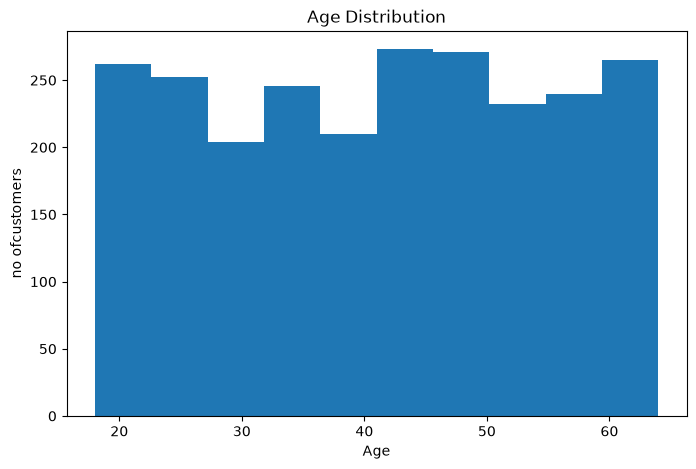

In [1047]:
#chacking the age distribution with "histogram" 
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df["age"],bins=10)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("no ofcustomers")
plt.show()

In [1048]:
#after checking the histogram or mean and median you can choose
#mean or median , choosethe better one 
# after choosing that fill that in NaN of age place

df["age"]=df["age"].fillna(df["age"].median())

#after that check the Nan values
df["age"].isnull().sum()

np.int64(0)

In [1049]:
df["city"].value_counts()

city
Mumbai       465
Hyderabad    410
Chennai      403
Pune         399
Bangalore    395
Delhi        384
Name: count, dtype: int64

In [1050]:
#fillthe missing valusin city with "unknown"
df["city"]=df["city"].fillna("unknown")
df["city"].isnull().sum()

np.int64(0)

In [1051]:
#now handle the avg session time column missing data 
#but before that using discibr ckeck that column
df["avg_session_time"].describe()
#the mean and median are extreamly close so choosing mean or median can do 

count    2459.000000
mean       62.719569
std        32.920546
min         5.130000
25%        34.570000
50%        62.590000
75%        90.650000
max       119.940000
Name: avg_session_time, dtype: float64

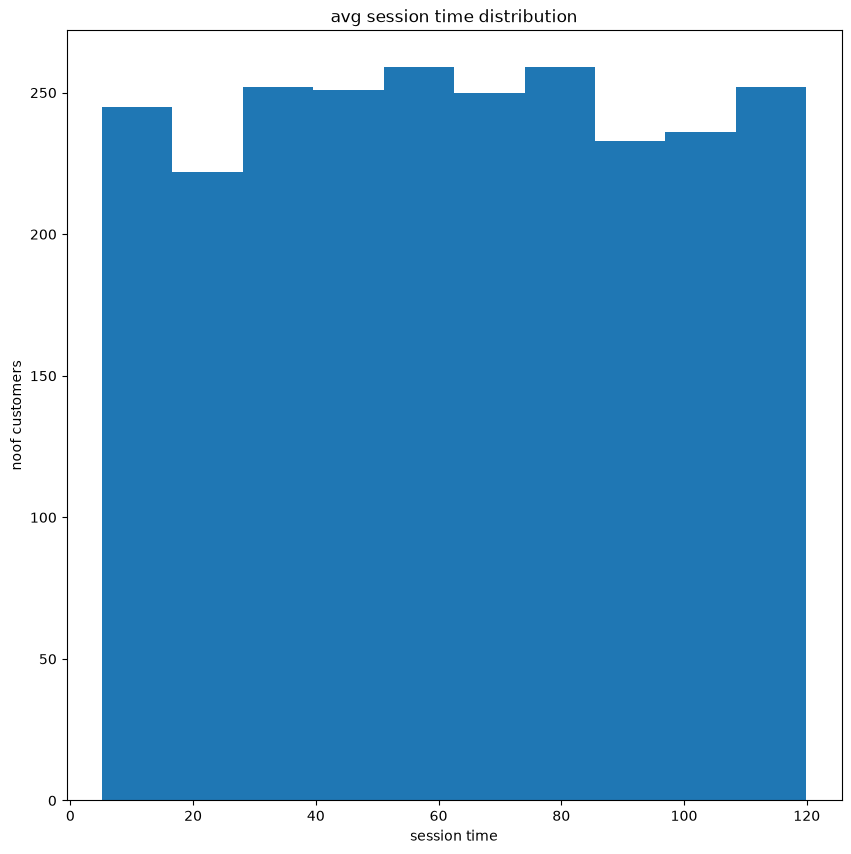

In [1052]:
# Examine the distribution of average session time before imputation.
plt.figure(figsize=(10,10))
plt.hist(df["avg_session_time"],bins=10)
plt.title("avg session time distribution")
plt.xlabel("session time")
plt.ylabel("noof customers")
plt.show()

In [1053]:
#now by choosing median
# Fill missing session time values with the median.
df["avg_session_time"]=df["avg_session_time"].fillna(df["avg_session_time"].median())

In [1054]:
# Check the distribution of discount percentage before imputation.
df["discount_percent"].describe()

count    2455.000000
mean       10.024440
std         7.096911
min         0.000000
25%         5.000000
50%        10.000000
75%        15.000000
max        20.000000
Name: discount_percent, dtype: float64

In [1055]:
# Fill missing discount values with the median.
df["discount_percent"] = df["discount_percent"].fillna(df["discount_percent"].median())

In [1056]:
# Verify that all missing values have been handled.
df.isnull().sum()

customer_id          0
age                  0
gender               0
city                 0
signup_date          0
last_active_date     0
plan_type            0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
marketing_channel    0
churned              0
total_revenue        0
dtype: int64

## 4.2 Duplicate Records

Duplicate records were identified and removed to prevent repeated customer records from affecting the analysis.

In [1057]:
# Count duplicate records before removal.
df.duplicated().sum()

np.int64(60)

In [1058]:
df=df.drop_duplicates()

In [1059]:
# Verify that duplicate records have been removed.
df.duplicated().sum()

np.int64(0)

In [1060]:
df[['signup_date', 'last_active_date']].head()

,signup_date,last_active_date
0,12/3/2022,12/29/2022
1,3/24/2021,1/25/2022
2,6/15/2023,8/10/2023
3,11/13/2022,7/8/2021
4,2/17/2022,6/25/2021


In [1061]:
df.dtypes

customer_id            int64
age                  float64
gender                   str
city                     str
signup_date              str
last_active_date         str
plan_type                str
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
marketing_channel        str
churned                  str
total_revenue        float64
dtype: object

## 4.3 Date Conversion

The signup and last active date columns were converted from string values into Pandas datetime format to support date-based analysis.

In [1062]:
df["signup_date"]=pd.to_datetime(df["signup_date"])
df["last_active_date"]=pd.to_datetime(df["last_active_date"])

In [1063]:
df['signup_date'].dtype

dtype('<M8[us]')

In [1064]:
(df['last_active_date'] < df['signup_date']).sum()

np.int64(852)

## 4.4 Date Consistency Check

The relationship between signup date and last active date was checked to identify records where the last active date occurred before the signup date.

In [1065]:
df[df['last_active_date'] < df['signup_date']][
    ['customer_id', 'signup_date', 'last_active_date']
].head(10)

,customer_id,signup_date,last_active_date
3,10004,2022-11-13,2021-07-08
4,10005,2022-02-17,2021-06-25
6,10007,2022-12-01,2022-09-04
8,10009,2023-03-12,2022-07-22
10,10011,2022-09-01,2022-06-18
12,10013,2022-06-12,2021-11-05
13,10014,2023-03-02,2022-12-21
14,10015,2022-10-09,2022-08-07
15,10016,2022-06-22,2021-07-18
16,10017,2023-05-14,2022-04-24


In [1066]:
invalid_dates = (df['last_active_date'] < df['signup_date']).sum()

invalid_percentage = invalid_dates / len(df) * 100

invalid_percentage
df[['signup_date', 'last_active_date']].describe()


,signup_date,last_active_date
count,2500,2500
mean,2022-04-01 07:04:30.720000,2022-09-03 10:59:31.200000
min,2021-01-01 00:00:00,2021-06-01 00:00:00
25%,2021-08-16 00:00:00,2022-01-21 00:00:00
50%,2022-03-26 00:00:00,2022-09-13 12:00:00
75%,2022-11-22 06:00:00,2023-04-16 00:00:00
max,2023-06-19 00:00:00,2023-11-17 00:00:00


### Finding
852 records had a last active date earlier than the signup date. These records were retained in the dataset rather than deleted, and the date inconsistency was tracked using a validation flag.
The `days_active` feature was not used in the initial revenue prediction model because these inconsistent dates could produce invalid negative durations.

In [1067]:
# 852 records have an invalid date order because
# last_active_date occurs before signup_date.
# These records are retained to avoid unnecessary data loss,
# but date-dependent calculations should handle them carefully.
df["date_valid"] = (
    df["last_active_date"] >= df["signup_date"]
)
df["date_valid"].value_counts()

date_valid
True     1648
False     852
Name: count, dtype: int64

## 4.5 Cleaning Verification

In [1068]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())

Rows: 2500
Columns: 16
Duplicate rows: 0


In [1069]:
df[['age', 'monthly_fee', 'tenure_months', 
    'support_tickets', 'avg_session_time',
    'discount_percent', 'total_revenue']].describe()

,age,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,total_revenue
count,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.00000
mean,41.13280,902.536000,17.784000,2.089600,62.645964,10.024000,15909.88380
std,13.29157,348.080219,10.062736,1.478122,32.239271,6.942529,11366.85225
min,18.00000,300.000000,1.000000,0.000000,5.130000,0.000000,288.15000
25%,30.00000,593.000000,9.000000,1.000000,35.480000,5.000000,6889.05000
50%,41.00000,911.500000,17.000000,2.000000,62.590000,10.000000,13457.82500
75%,52.00000,1205.000000,26.000000,3.000000,88.905000,15.000000,23251.37500
max,64.00000,1499.000000,35.000000,8.000000,119.940000,20.000000,50741.60000


# 5. Feature Engineering

New features were created from the existing customer attributes to support customer segmentation, behavioral analysis, churn analysis, and revenue analysis.

## 5.1 Customer Tenure Feature

In [1070]:
# Convert customer tenure from months to years.
df["cus_tenure_years"] = df["tenure_months"] / 12

df[["tenure_months", "cus_tenure_years"]].head()

,tenure_months,cus_tenure_years
0,25,2.083333
1,22,1.833333
2,4,0.333333
3,4,0.333333
4,30,2.500000


## 5.2 Revenue Features

In [1071]:
# Calculate average revenue per month for exploratory analysis.
# This feature is derived from total revenue and is excluded from revenue prediction models.

df["revenue_per_month"] = (
    df["total_revenue"] / df["tenure_months"]
)

df[["total_revenue", "tenure_months", "revenue_per_month"]].head()

,total_revenue,tenure_months,revenue_per_month
0,30167.90,25,1206.716000
1,27642.40,22,1256.472727
2,3092.85,4,773.212500
3,2180.00,4,545.000000
4,39796.90,30,1326.563333


## 5.3 Engagement Score
The engagement score combines average session time with support-ticket activity to create a simple behavioral indicator for exploratory analysis.

In [1072]:
df["engagement_score"] = (
    df["avg_session_time"] / (df["support_tickets"] + 1)
)
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue,date_valid,cus_tenure_years,revenue_per_month,engagement_score
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90,True,2.083333,1206.716000,2.625000
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40,True,1.833333,1256.472727,18.580000
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85,True,0.333333,773.212500,41.930000
3,10004,60.0,Male,Delhi,2022-11-13,2021-07-08,Standard,545,4,1,116.41,0.0,Organic,No,2180.00,False,0.333333,545.000000,58.205000
4,10005,25.0,Female,Mumbai,2022-02-17,2021-06-25,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90,False,2.500000,1326.563333,40.945000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80,True,1.083333,916.676923,14.980000
2496,12497,62.0,Male,Delhi,2023-04-29,2023-03-30,Standard,891,34,2,89.36,5.0,Ads,No,30249.45,False,2.833333,889.689706,29.786667
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50,True,2.000000,1359.312500,8.126000
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40,True,0.083333,790.400000,4.681667


In [1073]:
df[["avg_session_time", "support_tickets", "engagement_score"]].head()

,avg_session_time,support_tickets,engagement_score
0,15.75,5,2.625
1,37.16,1,18.580
2,41.93,0,41.930
3,116.41,1,58.205
4,81.89,1,40.945


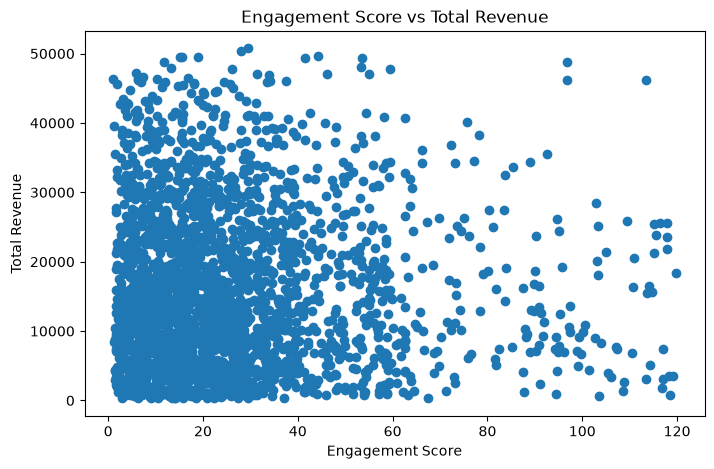

In [1074]:
#engagement score vs revenue (scatter plot)
plt.figure(figsize=(8, 5))

plt.scatter(
    df["engagement_score"],
    df["total_revenue"]
)

plt.title("Engagement Score vs Total Revenue")
plt.xlabel("Engagement Score")
plt.ylabel("Total Revenue")
plt.savefig("images/engagement_vs_revenue.png", dpi=300, bbox_inches="tight")

plt.show()

## 5.4 Date-Based Features

In [1075]:
# Extract date-based features from the already converted signup date.
df["signup_month"] = df["signup_date"].dt.to_period("M")

In [1076]:
# Calculate the number of customer signups by month.
signup_trend = df.groupby("signup_month")["customer_id"].count()
signup_trend

signup_month
2021-01     81
2021-02     66
2021-03     87
2021-04     89
2021-05     90
2021-06     75
2021-07     86
2021-08    101
2021-09     68
2021-10     96
2021-11     95
2021-12     84
2022-01     98
2022-02     70
2022-03     78
2022-04     67
2022-05     65
2022-06     87
2022-07     79
2022-08     84
2022-09     80
2022-10     90
2022-11     79
2022-12    107
2023-01     93
2023-02     74
2023-03     98
2023-04     91
2023-05     97
2023-06     45
Freq: M, Name: customer_id, dtype: int64

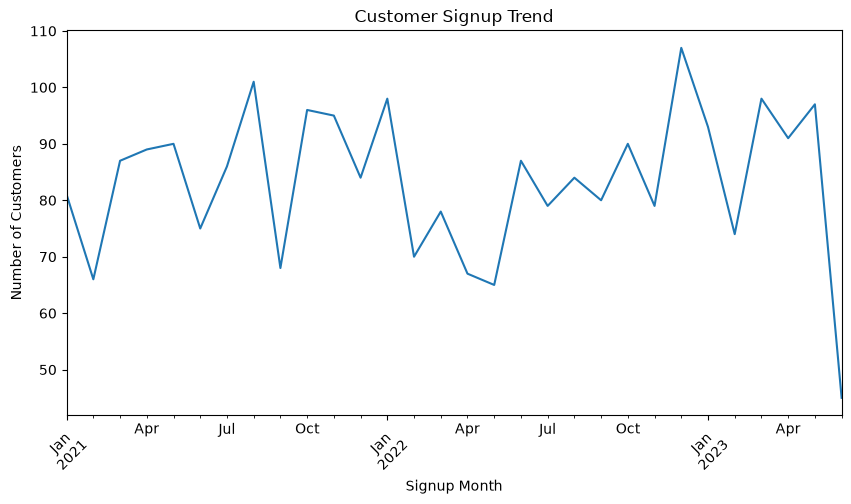

In [1077]:
#signup trend chart(line)
signup_trend.plot(kind="line", figsize=(10, 5))

plt.title("Customer Signup Trend")
plt.xlabel("Signup Month")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.savefig("images/signup_trend.png", dpi=300, bbox_inches="tight")
plt.show()

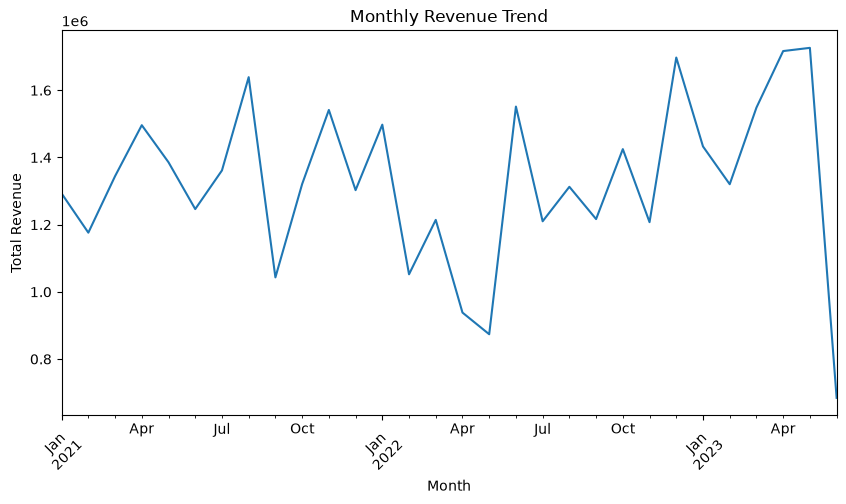

In [1078]:
# Monthly Revenue Trend

monthly_revenue = (
    df.groupby("signup_month")["total_revenue"]
      .sum()
)
monthly_revenue.plot(kind="line", figsize=(10, 5))

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.savefig("images/monthly_revenue_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [1079]:
df[[
    "monthly_fee",
    "tenure_months",
    "total_revenue",
    "revenue_per_month"
]].head(10)

,monthly_fee,tenure_months,total_revenue,revenue_per_month
0,1214,25,30167.90,1206.716000
1,1268,22,27642.40,1256.472727
2,783,4,3092.85,773.212500
3,545,4,2180.00,545.000000
4,1331,30,39796.90,1326.563333
5,451,2,834.35,417.175000
6,510,29,14790.00,510.000000
7,666,21,13886.10,661.242857
8,1243,21,25916.55,1234.121429
9,385,21,8027.25,382.250000


In [1080]:
df[["monthly_fee", "revenue_per_month"]].describe()

,monthly_fee,revenue_per_month
count,2500.000000,2500.000000
mean,902.536000,891.266067
std,348.080219,344.296802
min,300.000000,288.150000
25%,593.000000,588.055868
50%,911.500000,895.080952
75%,1205.000000,1191.856324
max,1499.000000,1497.000000


## 5.5 Customer Segmentation Features

Additional categorical features were created to segment customers by age, session usage, discount level, and revenue.

In [1081]:
# Segment customers into age groups.
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 50, 64],
    labels=["Young", "Adult", "Middle-aged", "Older"]
)

df[["age", "age_group"]].head(10)

,age,age_group
0,56.0,Older
1,46.0,Middle-aged
2,32.0,Adult
3,60.0,Older
4,25.0,Young
5,38.0,Middle-aged
6,56.0,Older
7,36.0,Middle-aged
8,40.0,Middle-aged
9,28.0,Adult


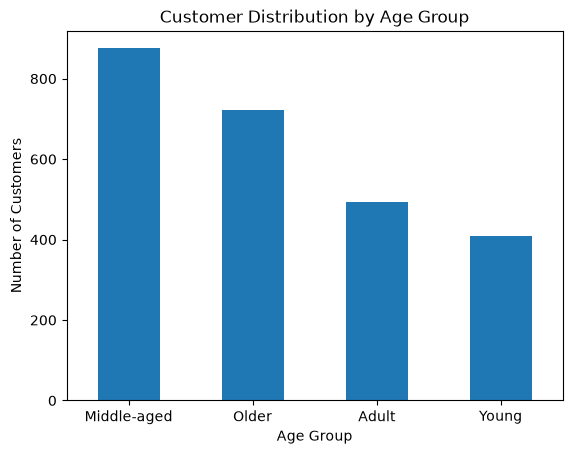

In [1082]:
# Visualize the distribution of customers across age groups.
df["age_group"].value_counts().plot(kind="bar")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.savefig(
    "images/customer_distribution_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5.6 Churn Feature

The original churn status was converted into a binary numerical flag for analysis and machine learning.

In [1083]:
df["churn_flag"] = df["churned"].map({
    "Yes": 1,
    "No": 0
})

## 5.7 Customer Value Features

A high-value customer indicator was created using the median total revenue as the threshold.

In [1084]:
# Classify customers as high-value based on median total revenue.
revenue_median = df["total_revenue"].median()

df["high_value_customer"] = df["total_revenue"].apply(
    lambda x: "Yes" if x >= revenue_median else "No"
)

## 5.8 Activity Duration Feature

The number of days between signup and last active date was calculated to represent customer activity duration.

Records with negative durations were treated as invalid because their last active date occurs before signup.

In [1085]:
# Calculate the number of days between signup and last activity.
df["days_active"] = (
    df["last_active_date"] - df["signup_date"]
).dt.days

df[["signup_date", "last_active_date", "days_active"]].head(10)

,signup_date,last_active_date,days_active
0,2022-12-03,2022-12-29,26
1,2021-03-24,2022-01-25,307
2,2023-06-15,2023-08-10,56
3,2022-11-13,2021-07-08,-493
4,2022-02-17,2021-06-25,-237
5,2021-06-16,2022-07-15,394
6,2022-12-01,2022-09-04,-88
7,2021-06-18,2022-12-23,553
8,2023-03-12,2022-07-22,-233
9,2021-08-17,2022-05-23,279


In [1086]:
df[["signup_date", "last_active_date", "days_active"]].head(10)

,signup_date,last_active_date,days_active
0,2022-12-03,2022-12-29,26
1,2021-03-24,2022-01-25,307
2,2023-06-15,2023-08-10,56
3,2022-11-13,2021-07-08,-493
4,2022-02-17,2021-06-25,-237
5,2021-06-16,2022-07-15,394
6,2022-12-01,2022-09-04,-88
7,2021-06-18,2022-12-23,553
8,2023-03-12,2022-07-22,-233
9,2021-08-17,2022-05-23,279


In [1087]:
# Count records with invalid negative activity duration.
(df["days_active"] < 0).sum()

np.int64(852)

In [1088]:
# Inspect examples of records with invalid activity duration.
df.loc[
    df["days_active"] < 0,
    ["signup_date", "last_active_date", "days_active"]
].head(10)

,signup_date,last_active_date,days_active
3,2022-11-13,2021-07-08,-493
4,2022-02-17,2021-06-25,-237
6,2022-12-01,2022-09-04,-88
8,2023-03-12,2022-07-22,-233
10,2022-09-01,2022-06-18,-75
12,2022-06-12,2021-11-05,-219
13,2023-03-02,2022-12-21,-71
14,2022-10-09,2022-08-07,-63
15,2022-06-22,2021-07-18,-339
16,2023-05-14,2022-04-24,-385


In [1089]:
# Replace invalid negative durations with missing values.
df["days_active"] = df["days_active"].where(
    df["days_active"] >= 0
)

df["days_active"].describe()

count    1648.000000
mean      363.669903
std       245.538691
min         0.000000
25%       155.000000
50%       329.000000
75%       542.000000
max      1015.000000
Name: days_active, dtype: float64

In [1090]:
# Categorize customers based on average session time.
df["session_usage_category"] = df["avg_session_time"].apply(
    lambda x: "Low" if x < 20
    else ("Medium" if x <= 60 else "High")
)

df[["avg_session_time", "session_usage_category"]].head(10)

,avg_session_time,session_usage_category
0,15.75,Low
1,37.16,Medium
2,41.93,Medium
3,116.41,High
4,81.89,High
5,53.99,Medium
6,118.63,High
7,22.62,Medium
8,59.75,Medium
9,79.41,High


In [1091]:
# Categorize customers based on discount percentage.
df["discount_category"] = df["discount_percent"].apply(
    lambda x: "Low" if x < 20
    else ("Medium" if x < 60 else "High"))
df[["discount_percent", "discount_category"]].head(10)

,discount_percent,discount_category
0,15.0,Low
1,20.0,Medium
2,5.0,Low
3,0.0,Low
4,10.0,Low
5,15.0,Low
6,0.0,Low
7,15.0,Low
8,15.0,Low
9,15.0,Low


## 5.9 Additional Analytical Features

Additional features were created to support customer support analysis, revenue segmentation, and subscription-plan comparisons.

In [1092]:
# Calculate support intensity relative to customer tenure.
df["support_intensity"] = (
    df["support_tickets"] / (df["tenure_months"] + 1)
)

In [1093]:
# Segment customers into revenue groups using quantiles.
df["revenue_category"] = pd.qcut(
    df["total_revenue"],
    q=3,
    labels=["Low", "Medium", "High"]
)

In [1094]:
# Assign a numerical rank to each subscription plan.
plan_rank = {
    "Basic": 1,
    "Standard": 2,
    "Premium": 3
}

df["plan_rank"] = df["plan_type"].map(plan_rank)

# 6. Exploratory Data Analysis

Exploratory data analysis was performed to understand customer characteristics, revenue patterns, engagement, signup trends, and relationships between numerical variables.

In [1095]:
# Compare total revenue generated by each subscription plan.
revenue_by_plan = df.groupby("plan_type")["total_revenue"].sum()

revenue_by_plan

plan_type
Basic       17111540.80
Premium      7657471.95
Standard    15005696.75
Name: total_revenue, dtype: float64

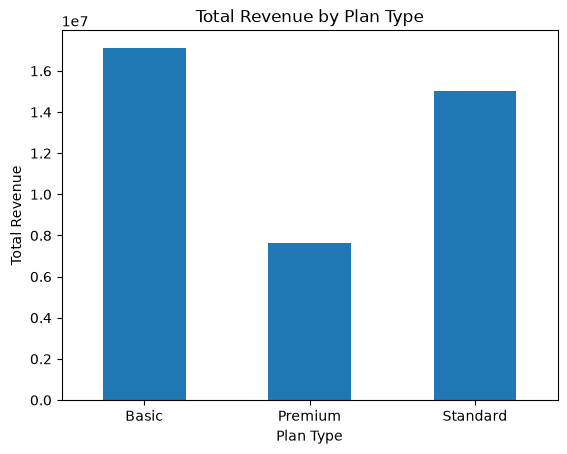

In [1096]:
#creating a bar chart 
revenue_by_plan.plot(kind="bar")

plt.title("Total Revenue by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.savefig("images/revenue_by_plantype.png", dpi=300, bbox_inches="tight")
plt.show()

In [1097]:
# Compare average revenue per customer across subscription plans.
average_revenue_by_plan = (
    df.groupby("plan_type")["total_revenue"]
      .mean()
)

average_revenue_by_plan

plan_type
Basic       15541.817257
Premium     15659.451840
Standard    16489.776648
Name: total_revenue, dtype: float64

In [1098]:
# Compare total revenue generated by each marketing channel.
revenue_by_channel = (
    df.groupby("marketing_channel")["total_revenue"]
      .sum()
)

revenue_by_channel

marketing_channel
Ads          9358576.00
Email       10446037.05
Organic     10089889.25
Referral     9880207.20
Name: total_revenue, dtype: float64

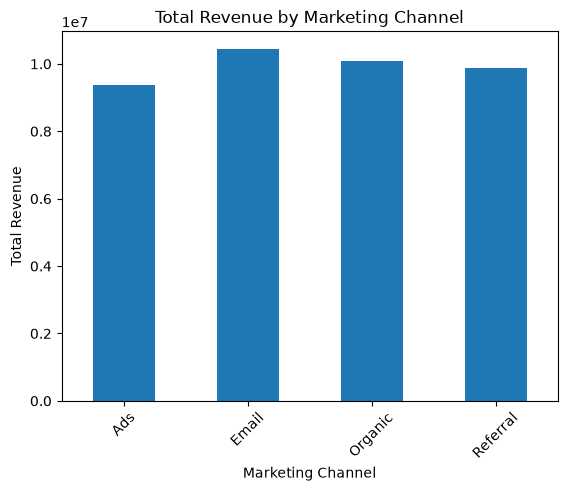

In [1099]:
#creating the bar chart for revenue_by_channel
revenue_by_channel.plot(kind="bar")

plt.title("Total Revenue by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.savefig("images/revenue_by_channel.png", dpi=300, bbox_inches="tight")
plt.show()

In [1100]:
revenue_by_channel.sort_values(ascending=False)

marketing_channel
Email       10446037.05
Organic     10089889.25
Referral     9880207.20
Ads          9358576.00
Name: total_revenue, dtype: float64

In [1101]:
# Identify the top five cities by total revenue.
revenue_by_city=df.groupby("city")["total_revenue"].sum()
revenue_by_city
top_5_cities=revenue_by_city.sort_values(ascending=False).head(5)
top_5_cities

city
Mumbai       7370886.15
Hyderabad    6293485.05
Bangalore    6157425.05
Pune         6150315.30
Chennai      6079883.95
Name: total_revenue, dtype: float64

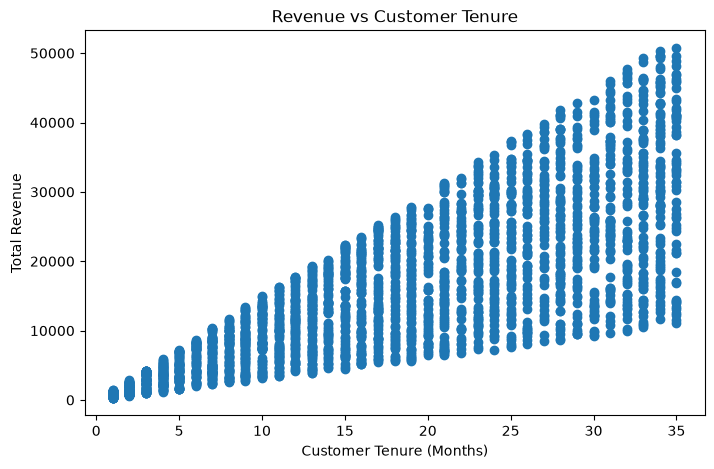

In [1102]:
# Examine the relationship between customer tenure and total revenue.
plt.figure(figsize=(8, 5))

plt.scatter(
    df["tenure_months"],
    df["total_revenue"]
)

plt.title("Revenue vs Customer Tenure")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Total Revenue")

plt.show()

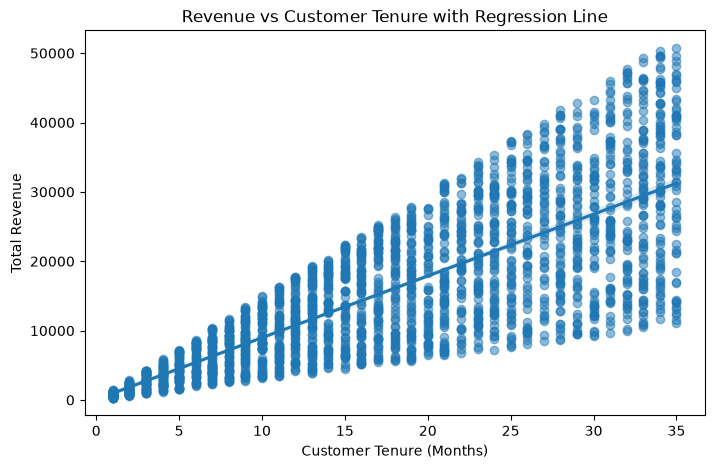

In [1103]:
# Visualize the linear trend between customer tenure and total revenue.
plt.figure(figsize=(8,5))
sns.regplot(data=df,
            x="tenure_months",
            y="total_revenue",
            scatter_kws={"alpha":0.5})
plt.title("Revenue vs Customer Tenure with Regression Line")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Total Revenue")

plt.savefig("images/revenue_vs_tenure.png", dpi=300, bbox_inches="tight")

plt.show()

In [1104]:
# Analyze total revenue by customer signup month.
df["signup_revenue_month"] = df["signup_date"].dt.to_period("M")

monthly_revenue = (
    df.groupby("signup_revenue_month")["total_revenue"]
      .sum()
)

monthly_revenue

signup_revenue_month
2021-01    1292796.05
2021-02    1176158.10
2021-03    1344305.35
2021-04    1496045.90
2021-05    1385676.80
2021-06    1246340.50
2021-07    1361372.75
2021-08    1639030.55
2021-09    1043027.10
2021-10    1320735.20
2021-11    1541400.60
2021-12    1302711.40
2022-01    1497598.90
2022-02    1052229.40
2022-03    1214197.00
2022-04     938274.00
2022-05     873780.70
2022-06    1551477.05
2022-07    1209993.15
2022-08    1312654.55
2022-09    1216585.00
2022-10    1424784.50
2022-11    1207391.35
2022-12    1697374.50
2023-01    1432753.95
2023-02    1320297.95
2023-03    1548368.25
2023-04    1716668.30
2023-05    1726202.45
2023-06     684478.20
Freq: M, Name: total_revenue, dtype: float64

In [1105]:
# Calculate correlations among numerical variables.
numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

correlation_matrix

,customer_id,age,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,total_revenue,cus_tenure_years,revenue_per_month,engagement_score,churn_flag,days_active,support_intensity,plan_rank
customer_id,1.000000,-0.004528,0.022782,-0.011027,0.000629,-0.015720,-0.040710,0.001082,-0.011027,0.025042,-0.019971,0.026709,-0.041473,0.001558,0.031332
age,-0.004528,1.000000,0.009825,-0.011053,0.026178,0.070030,0.021648,0.005458,-0.011053,0.008502,0.037359,-0.020664,-0.018969,0.028798,0.005365
monthly_fee,0.022782,0.009825,1.000000,-0.014322,-0.022074,-0.009464,0.005308,0.523972,-0.014322,0.997411,-0.003981,0.001055,0.002843,-0.020085,-0.009562
tenure_months,-0.011027,-0.011053,-0.014322,1.000000,-0.000824,-0.012799,-0.022723,0.788242,1.000000,0.017212,-0.013505,-0.023879,-0.008533,-0.530970,0.024034
support_tickets,0.000629,0.026178,-0.022074,-0.000824,1.000000,0.012277,-0.009763,-0.009172,-0.000824,-0.020775,-0.575977,0.004149,0.014102,0.473486,0.003151
avg_session_time,-0.015720,0.070030,-0.009464,-0.012799,0.012277,1.000000,0.002049,-0.021666,-0.012799,-0.009091,0.614386,0.001163,0.006034,0.001258,0.005178
discount_percent,-0.040710,0.021648,0.005308,-0.022723,-0.009763,0.002049,1.000000,-0.021996,-0.022723,-0.017818,-0.004619,-0.010075,0.006316,0.013914,-0.012931
total_revenue,0.001082,0.005458,0.523972,0.788242,-0.009172,-0.021666,-0.021996,1.000000,0.788242,0.551973,-0.019075,-0.019961,-0.015571,-0.424208,0.013113
cus_tenure_years,-0.011027,-0.011053,-0.014322,1.000000,-0.000824,-0.012799,-0.022723,0.788242,1.000000,0.017212,-0.013505,-0.023879,-0.008533,-0.530970,0.024034
revenue_per_month,0.025042,0.008502,0.997411,0.017212,-0.020775,-0.009091,-0.017818,0.551973,0.017212,1.000000,-0.004506,0.000319,0.001649,-0.054215,-0.009317


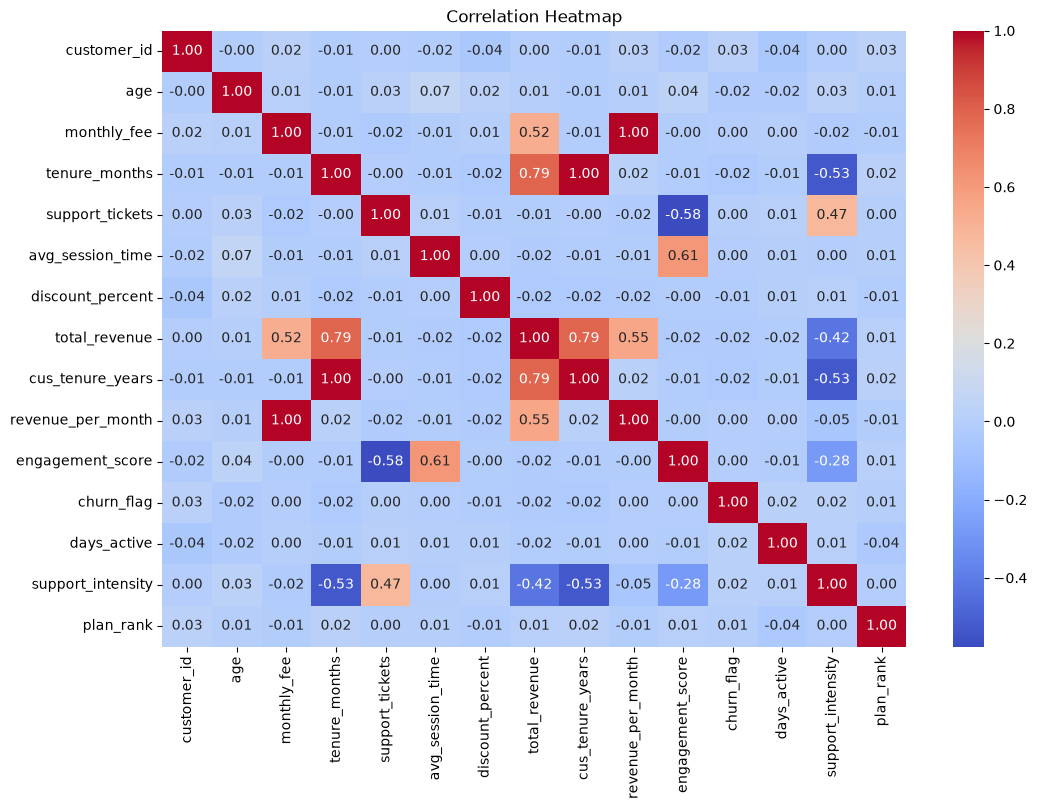

In [1106]:
# Visualize correlations among numerical variables.
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.savefig("images/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# 7. Churn Analysis

Customer churn was analyzed across key customer and subscription attributes to identify differences in observed churn rates between customer segments.

In [1107]:
# Calculate overall churn distribution and churn rate.
churn_summary = df["churned"].value_counts()

print("Customer churn distribution:")
print(churn_summary)

churn_rate = df["churn_flag"].mean() * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")

Customer churn distribution:
churned
No     1914
Yes     586
Name: count, dtype: int64

Overall churn rate: 23.44%


In [1108]:

# Compare observed churn rates across subscription plans.

churn_by_plan = (
    df.groupby("plan_type")["churn_flag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

churn_by_plan

plan_type
Premium     26.584867
Basic       24.250681
Standard    20.769231
Name: churn_flag, dtype: float64

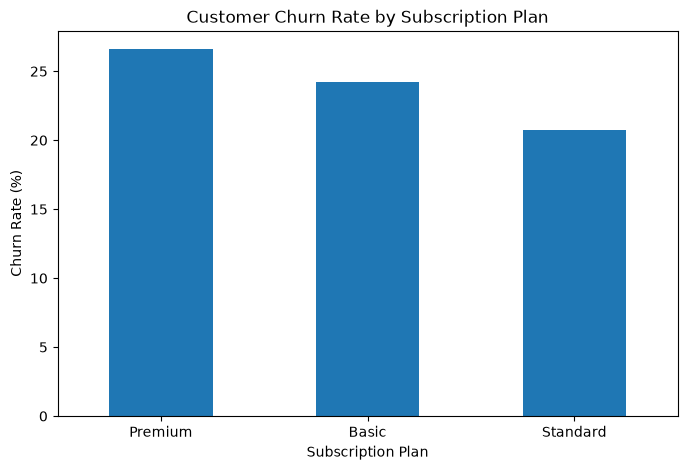

In [1109]:
plt.figure(figsize=(8, 5))

churn_by_plan.plot(kind="bar")

plt.title("Customer Churn Rate by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.savefig(
    "images/churn_rate_by_plan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1110]:

# Group customers by tenure duration
tenure_bins = [0, 6, 12, 24, float("inf")]
tenure_labels = [
    "0-6 months",
    "7-12 months",
    "13-24 months",
    "25+ months"
]

df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

churn_by_tenure_group = (
    df.groupby("tenure_group", observed=True)["churn_flag"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

display(churn_by_tenure_group)

print(
    "Customers without a tenure group:",
    df["tenure_group"].isna().sum()
)


,tenure_group,churn_rate
0,0-6 months,27.163462
1,7-12 months,23.076923
2,13-24 months,22.437358
3,25+ months,22.769640


Customers without a tenure group: 0


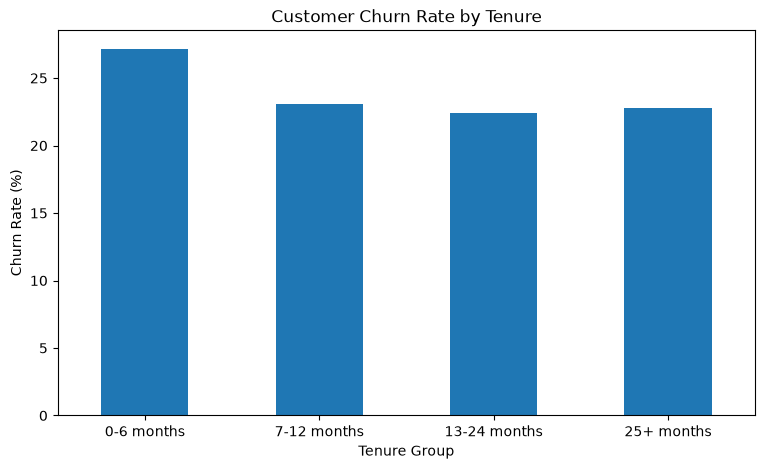

In [1111]:
plt.figure(figsize=(9, 5))

tenure_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.savefig(
    "images/churn_rate_by_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1112]:
#Do customers with more support tickets show different observed churn rates?
# Churn rate by support ticket count
# Group customers by support-ticket volume.
support_bins = [-1, 1, 3, 5, float("inf")]
support_labels = [
    "0–1 tickets",
    "2–3 tickets",
    "4–5 tickets",
    "6+ tickets"
]

df["support_ticket_group"] = pd.cut(
    df["support_tickets"],
    bins=support_bins,
    labels=support_labels
)

support_churn = (
    df.groupby("support_ticket_group", observed=True)["churn_flag"]
      .agg(
          customers="count",
          churn_rate="mean"
      )
)

support_churn["churn_rate"] = support_churn["churn_rate"] * 100

support_churn

,customers,churn_rate
support_ticket_group,,
0–1 tickets,975,22.256410
2–3 tickets,1124,24.466192
4–5 tickets,334,23.952096
6+ tickets,67,20.895522


<Figure size 1000x500 with 0 Axes>

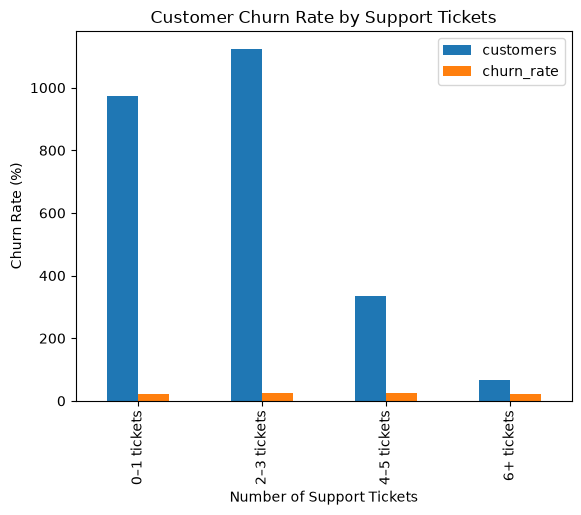

In [1113]:
plt.figure(figsize=(10, 5))

support_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Support Tickets")
plt.xlabel("Number of Support Tickets")
plt.ylabel("Churn Rate (%)")

plt.savefig(
    "images/churn_rate_by_support_tickets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Engagement and Churn

Engagement scores were compared between churned and retained customers to determine whether a clear difference was present in this dataset.

In [1114]:
# Compare engagement scores between churned and retained customers.

engagement_churn = (
    df.groupby("churned")["engagement_score"]
      .agg(["mean", "median", "count"])
)

engagement_churn

,mean,median,count
churned,,,
No,26.201392,20.863333,1914
Yes,26.257989,20.728333,586


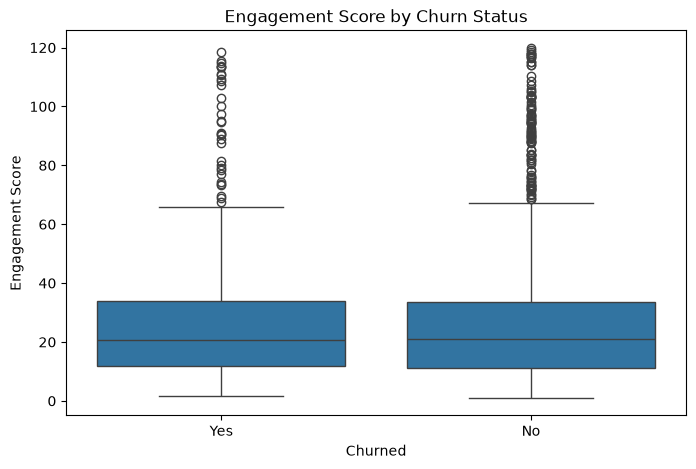

In [1115]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churned",
    y="engagement_score"
)

plt.title("Engagement Score by Churn Status")
plt.xlabel("Churned")
plt.ylabel("Engagement Score")

plt.savefig(
    "images/engagement_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1116]:
# Compare observed churn rates across marketing channels.

channel_churn = (
    df.groupby("marketing_channel")["churn_flag"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

channel_churn

marketing_channel
Email       25.153374
Organic     23.754153
Referral    22.605965
Ads         22.167488
Name: churn_flag, dtype: float64

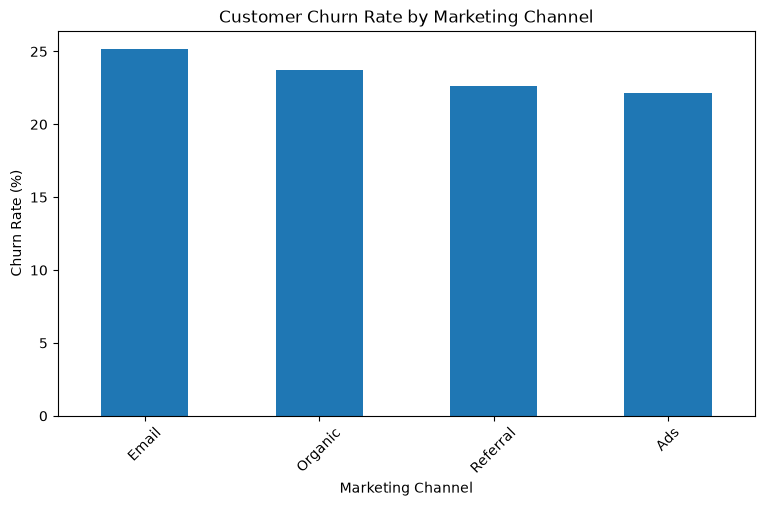

In [1117]:
plt.figure(figsize=(9, 5))

channel_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)

plt.savefig(
    "images/churn_rate_by_marketing_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1118]:
# Churn among high-value customers

high_value_churn = (
    pd.crosstab(
        df["high_value_customer"],
        df["churned"],
        normalize="index"
    ) * 100
)

high_value_churn

churned,No,Yes
high_value_customer,,
No,75.68,24.32
Yes,77.44,22.56


## Churn Analysis Summary

The churn analysis examined differences in observed churn rates across:

- Subscription plans
- Customer tenure
- Support ticket activity
- Engagement levels
- Marketing channels
- High-value customer segments

These analyses are used to identify customer segments that may require
further investigation and to provide business context for the churn
prediction model developed later in the project.

# 8. Churn Prediction

The churn prediction model evaluates whether customer and subscription characteristics can be used to distinguish between churned and retained customers.

Only features appropriate for the prediction task are used, while variables derived directly from the churn outcome or revenue target are excluded.

In [1119]:
# Defining features for churn prediction

churn_features = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent",
    "plan_type",
    "marketing_channel"
]

X_churn = df[churn_features].copy()

y_churn = df["churn_flag"].copy()

X_churn.head()

,age,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,plan_type,marketing_channel
0,56.0,1214,25,5,15.75,15.0,Basic,Referral
1,46.0,1268,22,1,37.16,20.0,Premium,Organic
2,32.0,783,4,0,41.93,5.0,Basic,Referral
3,60.0,545,4,1,116.41,0.0,Standard,Organic
4,25.0,1331,30,1,81.89,10.0,Basic,Ads


In [1120]:

# Verify the churn target encoding
df.groupby("churned")["churn_flag"].agg(
    min_value="min",
    max_value="max",
    unique_values="nunique"
)


,min_value,max_value,unique_values
churned,,,
No,0,0,1
Yes,1,1,1


In [1121]:
# Check missing values in churn model features

X_churn.isnull().sum()


age                  0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
plan_type            0
marketing_channel    0
dtype: int64

In [1122]:
# Check churn target distribution

y_churn.value_counts()

churn_flag
0    1914
1     586
Name: count, dtype: int64

In [1123]:
y_churn.value_counts(normalize=True).mul(100)

churn_flag
0    76.56
1    23.44
Name: proportion, dtype: float64

In [1124]:
X_churn.dtypes

age                  float64
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
plan_type                str
marketing_channel        str
dtype: object

In [1125]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_churn,
    y_churn,
    test_size=0.20,
    random_state=42,
    stratify=y_churn
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 2000
Testing rows: 500


### 8.1 Logistic Regression — Churn Prediction

Logistic Regression is used as the baseline classification model because the target variable represents two outcomes: churn and non-churn.

The model estimates the probability that a customer belongs to the churn class.

In [1126]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

In [1127]:
numeric_features = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent"
]

categorical_features = [
    "plan_type",
    "marketing_channel"
]

In [1128]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [1129]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [1130]:

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")


Logistic Regression training completed.


In [1131]:

# Predict churn probabilities for the test customers
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Use the default threshold initially
y_pred_logistic = (y_prob_logistic >= 0.50).astype(int)


In [1132]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)
roc_auc = roc_auc_score(y_test, y_prob_logistic)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1 Score : {f1:.3f}")
print(f"ROC-AUC  : {roc_auc:.3f}")


Accuracy : 0.540
Precision: 0.277
Recall   : 0.598
F1 Score : 0.378
ROC-AUC  : 0.543


In [1133]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Logistic Regression Results")
print("Accuracy :", round(accuracy_score(y_test, y_pred_logistic), 3))
print("Precision:", round(precision_score(
    y_test, y_pred_logistic, zero_division=0
), 3))
print("Recall   :", round(recall_score(
    y_test, y_pred_logistic, zero_division=0
), 3))
print("F1 Score :", round(f1_score(
    y_test, y_pred_logistic, zero_division=0
), 3))
print("ROC-AUC  :", round(roc_auc_score(
    y_test, y_prob_logistic
), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))


Logistic Regression Results
Accuracy : 0.54
Precision: 0.277
Recall   : 0.598
F1 Score : 0.378
ROC-AUC  : 0.543

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.52      0.63       383
           1       0.28      0.60      0.38       117

    accuracy                           0.54       500
   macro avg       0.54      0.56      0.51       500
weighted avg       0.68      0.54      0.57       500


Confusion Matrix:
[[200 183]
 [ 47  70]]


In [1134]:

# Compare Logistic Regression classification thresholds
threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (y_prob_logistic >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Customers Flagged": int(predictions.sum()),
        "True Positives": int(tp),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)
threshold_comparison.round(3)


,Threshold,Customers Flagged,True Positives,False Positives,False Negatives,Precision,Recall,F1 Score
0,0.3,500,117,383,0,0.234,1.000,0.379
1,0.4,500,117,383,0,0.234,1.000,0.379
2,0.5,253,70,183,47,0.277,0.598,0.378
3,0.6,0,0,0,117,0.000,0.000,0.000
4,0.7,0,0,0,117,0.000,0.000,0.000


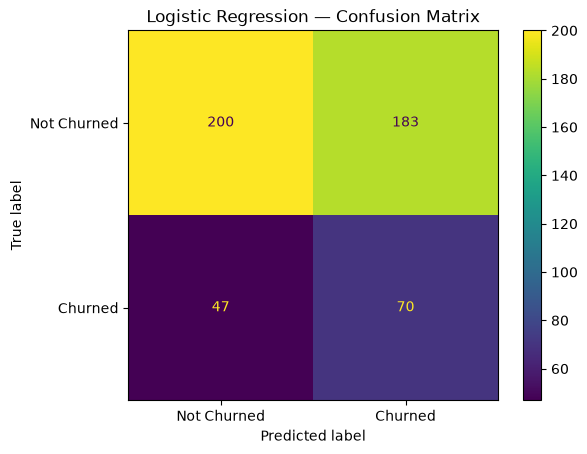

In [1135]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churned", "Churned"]
)

disp.plot()

plt.title("Logistic Regression — Confusion Matrix")

plt.savefig(
    "images/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8.2 Random Forest — Churn Prediction

Random Forest is an ensemble classification algorithm that combines
multiple decision trees.

It is used to investigate whether nonlinear relationships between
customer characteristics can improve churn prediction.

In [1136]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"))
        ])
random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [1137]:

print("Random Forest Results")

print("Accuracy :", round(
    accuracy_score(y_test, y_pred_rf), 3
))
print("Precision:", round(
    precision_score(y_test, y_pred_rf, zero_division=0), 3
))
print("Recall   :", round(
    recall_score(y_test, y_pred_rf, zero_division=0), 3
))
print("F1 Score :", round(
    f1_score(y_test, y_pred_rf, zero_division=0), 3
))
print("ROC-AUC  :", round(
    roc_auc_score(y_test, y_prob_rf), 3
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Results
Accuracy : 0.716
Precision: 0.209
Recall   : 0.077
F1 Score : 0.113
ROC-AUC  : 0.528

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.91      0.83       383
           1       0.21      0.08      0.11       117

    accuracy                           0.72       500
   macro avg       0.49      0.49      0.47       500
weighted avg       0.63      0.72      0.66       500


Confusion Matrix:
[[349  34]
 [108   9]]


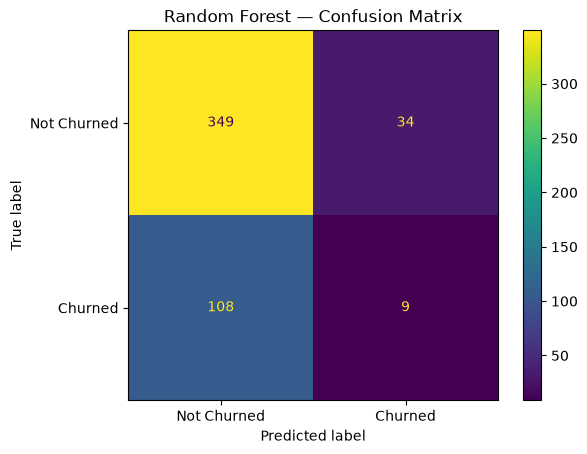

In [1138]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Churned", "Churned"]
)

disp.plot()

plt.title("Random Forest — Confusion Matrix")

plt.savefig(
    "images/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1139]:

# Compare Random Forest classification thresholds
rf_threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (y_prob_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Customers Flagged": int(predictions.sum()),
        "True Positives": int(tp),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

rf_threshold_comparison = pd.DataFrame(rf_threshold_results)
rf_threshold_comparison.round(3)


,Threshold,Customers Flagged,True Positives,False Positives,False Negatives,Precision,Recall,F1 Score
0,0.3,357,89,268,28,0.249,0.761,0.376
1,0.4,152,38,114,79,0.250,0.325,0.283
2,0.5,49,9,40,108,0.184,0.077,0.108
3,0.6,10,1,9,116,0.100,0.009,0.016
4,0.7,1,0,1,117,0.000,0.000,0.000


## 8.3 Random Forest Feature Importance

Feature importance is used to identify which customer attributes contribute
most to the Random Forest's predictions.

These results describe model behavior and should not be interpreted as
causal relationships.

In [1140]:
feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = random_forest_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(
    "importance",
    ascending=False
)

feature_importance.head(15)

,feature,importance
4,num__avg_session_time,0.201232
1,num__monthly_fee,0.195988
0,num__age,0.166184
2,num__tenure_months,0.157480
3,num__support_tickets,0.089955
5,num__discount_percent,0.077269
11,cat__marketing_channel_Organic,0.018035
9,cat__marketing_channel_Ads,0.017805
12,cat__marketing_channel_Referral,0.017651
10,cat__marketing_channel_Email,0.017436


## 8.4 Churn Rate by Key Customer Attributes

The Random Forest identified customer activity, pricing, age, and tenure
as the most influential features in its predictions.

We therefore examine their relationship with churn using grouped analysis.
These results describe associations in the dataset and do not imply causation.

In [1141]:
churn_by_tenure = (
    df.groupby("tenure_months", observed=True)["churn_flag"]
    .mean()
    .reset_index()
)

churn_by_tenure["churn_rate"] = churn_by_tenure["churn_flag"] * 100

churn_by_tenure.head(15)

,tenure_months,churn_flag,churn_rate
0,1,0.266667,26.666667
1,2,0.183099,18.309859
2,3,0.323529,32.352941
3,4,0.333333,33.333333
4,5,0.305556,30.555556
5,6,0.213115,21.311475
6,7,0.235294,23.529412
7,8,0.200000,20.000000
8,9,0.197368,19.736842
9,10,0.280488,28.048780


In [1142]:
session_bins = [0, 10, 20, 30, 45, float("inf")]
session_labels = [
    "0–10 min",
    "11–20 min",
    "21–30 min",
    "31–45 min",
    "46+ min"
]

df["session_time_group"] = pd.cut(
    df["avg_session_time"],
    bins=session_bins,
    labels=session_labels
)

churn_by_session = (
    df.groupby("session_time_group", observed=True)["churn_flag"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

churn_by_session

,session_time_group,churn_rate
0,0–10 min,14.444444
1,11–20 min,24.413146
2,21–30 min,18.274112
3,31–45 min,27.414330
4,46+ min,23.645027


In [1143]:
fee_bins = [0, 300, 500, 700, 1000, float("inf")]
fee_labels = [
    "≤300",
    "301–500",
    "501–700",
    "701–1000",
    "1000+"
]

df["monthly_fee_group"] = pd.cut(
    df["monthly_fee"],
    bins=fee_bins,
    labels=fee_labels
)

churn_by_fee = (
    df.groupby("monthly_fee_group", observed=True)["churn_flag"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

churn_by_fee

,monthly_fee_group,churn_rate
0,≤300,50.000000
1,301–500,22.355769
2,501–700,22.748815
3,701–1000,25.380711
4,1000+,23.012161


In [1144]:
fee_analysis = (
    df.groupby("monthly_fee_group", observed=True)["churn_flag"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

fee_analysis["churn_rate"] = fee_analysis["churn_rate"] * 100

fee_analysis

,monthly_fee_group,customers,churned,churn_rate
0,≤300,2,1,50.000000
1,301–500,416,93,22.355769
2,501–700,422,96,22.748815
3,701–1000,591,150,25.380711
4,1000+,1069,246,23.012161


In [1145]:
support_bins = [-1, 1, 3, 5, float("inf")]
support_labels = [
    "0–1 tickets",
    "2–3 tickets",
    "4–5 tickets",
    "6+ tickets"
]

df["support_ticket_group"] = pd.cut(
    df["support_tickets"],
    bins=support_bins,
    labels=support_labels
)

churn_by_support = (
    df.groupby("support_ticket_group", observed=True)["churn_flag"]
    .agg(
        customers="count",
        churned="sum",
        churn_rate="mean"
    )
    .reset_index()
)

churn_by_support["churn_rate"] = (
    churn_by_support["churn_rate"] * 100
)

churn_by_support

,support_ticket_group,customers,churned,churn_rate
0,0–1 tickets,975,217,22.256410
1,2–3 tickets,1124,275,24.466192
2,4–5 tickets,334,80,23.952096
3,6+ tickets,67,14,20.895522


In [1146]:
churn_risk = X_test.copy()

churn_risk["actual_churn"] = y_test.values
churn_risk["churn_probability"] = y_prob_rf

churn_risk["risk_level"] = pd.cut(
    churn_risk["churn_probability"],
    bins=[0, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

churn_risk = churn_risk.sort_values(
    "churn_probability",
    ascending=False
)

churn_risk.head(10)

,age,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,plan_type,marketing_channel,actual_churn,churn_probability,risk_level
1414,42.0,1010,29,3,49.21,10.0,Premium,Referral,0,0.710,High
256,40.0,1346,21,0,63.74,20.0,Basic,Organic,0,0.675,High
1032,54.0,1247,6,0,94.21,5.0,Basic,Referral,0,0.665,High
2127,30.0,888,34,2,11.37,5.0,Basic,Ads,0,0.640,High
2161,46.0,855,30,1,25.51,20.0,Standard,Ads,1,0.635,High
239,36.0,572,4,3,78.56,20.0,Standard,Referral,0,0.625,High
2287,27.0,858,11,3,41.28,15.0,Standard,Ads,0,0.615,High
1351,34.0,932,35,4,25.46,15.0,Premium,Ads,0,0.615,High
1895,25.0,328,19,2,52.69,10.0,Premium,Organic,0,0.610,High
2198,23.0,1249,16,1,97.04,5.0,Basic,Ads,0,0.605,High


## 8.5 Model-Based Churn Risk Scoring


Random Forest probabilities are used to explore customer-level churn
risk scoring. The model has limited ability to distinguish churners
from retained customers, so the scores and risk categories are
experimental and should not be used directly for customer outreach
or business decisions without further validation.


In [1147]:
risk_summary = (
    churn_risk.groupby("risk_level", observed=True)
    .agg(
        customers=("actual_churn", "count"),
        actual_churned=("actual_churn", "sum"),
        average_predicted_probability=("churn_probability", "mean")
    )
    .reset_index()
)

risk_summary["actual_churn_rate"] = (
    risk_summary["actual_churned"]
    / risk_summary["customers"]
    * 100
)

risk_summary


,risk_level,customers,actual_churned,average_predicted_probability,actual_churn_rate
0,Low,154,29,0.247078,18.831169
1,Medium,336,87,0.398304,25.892857
2,High,10,1,0.639500,10.000000


# 9. Machine Learning Revenue Prediction

Machine learning was used to predict customer total revenue using customer and subscription characteristics.

The revenue prediction workflow includes feature selection, model training, prediction, evaluation, and interpretation of model results.

## 9.1 Define Features and Target

In [1148]:
# Define features and target for revenue prediction.
revenue_features = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent",
    "plan_rank",
    "support_intensity",
    "engagement_score"
]

X = df[revenue_features].copy()
y = df["total_revenue"].copy()

print("Missing values in revenue features:")
print(X.isnull().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Missing values in revenue features:
age                  0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
plan_rank            0
support_intensity    0
engagement_score     0
dtype: int64

Missing values in target:
0


In [1149]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 2000
Testing rows: 500


In [1150]:
from sklearn.linear_model import LinearRegression

# Create and train the Linear Regression model.
model = LinearRegression()

model.fit(X_train, y_train)

# Generate revenue predictions for the test set.
y_pred = model.predict(X_test)

In [1151]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10)

,Actual,Predicted
0,30480.45,29513.295636
1,3642.00,8041.010628
2,12978.00,17384.459013
3,9309.30,8844.106839
4,23195.70,25991.236016
5,18495.00,19171.369239
6,9024.60,8951.217359
7,3456.00,-1075.591675
8,33571.40,30328.242575
9,8265.90,14020.659027


In [1152]:
comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison.head(10)

,Actual,Predicted,Error
0,30480.45,29513.295636,967.154364
1,3642.00,8041.010628,-4399.010628
2,12978.00,17384.459013,-4406.459013
3,9309.30,8844.106839,465.193161
4,23195.70,25991.236016,-2795.536016
5,18495.00,19171.369239,-676.369239
6,9024.60,8951.217359,73.382641
7,3456.00,-1075.591675,4531.591675
8,33571.40,30328.242575,3243.157425
9,8265.90,14020.659027,-5754.759027


## 9.2 Model Evaluation

In [1153]:
# Mean Absolute Error (MAE)
# MAE represents the average absolute difference between
# actual and predicted revenue values.
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 2601.154891454013


In [1154]:
# Root Mean Squared Error (RMSE)
# RMSE gives greater weight to larger prediction errors.
from sklearn.metrics import mean_squared_error
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MSE:", mse)
print("RMSE:", rmse)

MSE: 12132206.062028801
RMSE: 3483.1316458079505


In [1155]:
# R² measures how much of the variation in revenue
# is explained by the model on the test dataset.
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R²:", r2)
#Metric result    	Meaning
# MAE	₹2,601.16	Average absolute prediction error
# RMSE	₹3,483.13	Gives more weight to larger errors
# R²	0.9019  	Model explains about 90.19% of the variation in revenue on the test data

R²: 0.9019174297276056


## 9.3 Actual vs Predicted Revenue

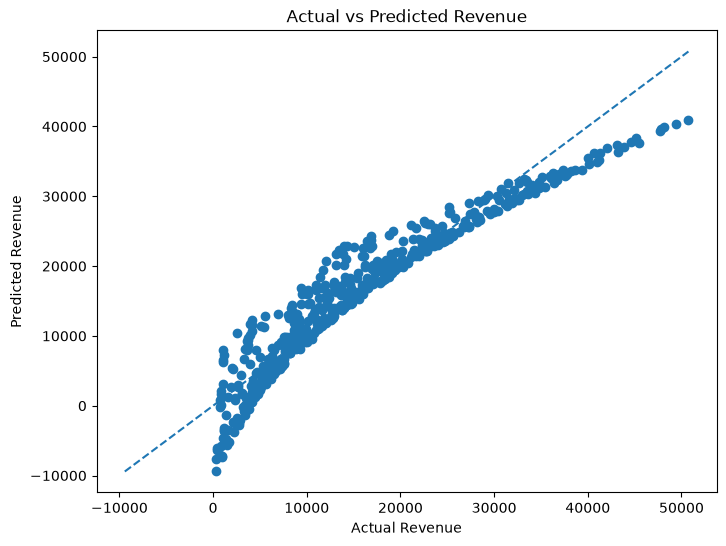

In [1156]:
#Now let's visualize the model
#Actual Revenue vs Predicted Revenue
# We'll create a scatter plot.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

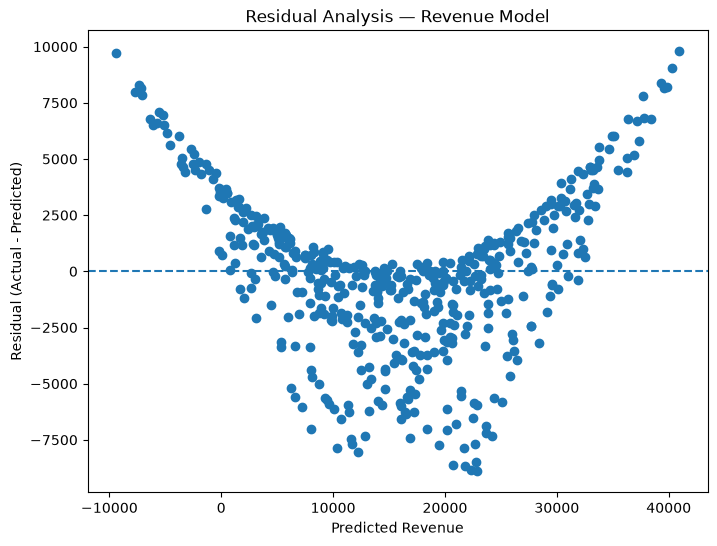

In [1157]:
# Calculate residuals
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Revenue")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis — Revenue Model")

plt.show()

## 9.4 Random Forest Regression — Revenue Prediction

In [1158]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

rf_revenue = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Train the model
rf_revenue.fit(X_train, y_train)

# Make predictions
y_pred_rf_revenue = rf_revenue.predict(X_test)

# Evaluate
rf_r2 = r2_score(y_test, y_pred_rf_revenue)
rf_mae = mean_absolute_error(y_test, y_pred_rf_revenue)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf_revenue))

print("Random Forest Revenue Model")
print("R²:", rf_r2)
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)

Random Forest Revenue Model
R²: 0.9990348886871588
MAE: 241.1375410000009
RMSE: 345.5116321977455


In [1159]:
# Check Random Forest performance on training data

y_pred_rf_train = rf_revenue.predict(X_train)

train_r2 = r2_score(y_train, y_pred_rf_train)
train_mae = mean_absolute_error(y_train, y_pred_rf_train)
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_rf_train))

print("Random Forest Training Performance")
print("R²:", train_r2)
print("MAE:", train_mae)
print("RMSE:", train_rmse)

Random Forest Training Performance
R²: 0.9998604371098813
MAE: 91.25470250000028
RMSE: 134.93997024673124


In [1160]:
# Check how closely revenue is related to monthly fee × tenure

df["base_revenue"] = df["monthly_fee"] * df["tenure_months"]

df[[
    "monthly_fee",
    "tenure_months",
    "base_revenue",
    "total_revenue"
]].head(10)

,monthly_fee,tenure_months,base_revenue,total_revenue
0,1214,25,30350,30167.90
1,1268,22,27896,27642.40
2,783,4,3132,3092.85
3,545,4,2180,2180.00
4,1331,30,39930,39796.90
5,451,2,902,834.35
6,510,29,14790,14790.00
7,666,21,13986,13886.10
8,1243,21,26103,25916.55
9,385,21,8085,8027.25


In [1161]:
print(
    "Correlation between base revenue and total revenue:",
    df["base_revenue"].corr(df["total_revenue"])
)

Correlation between base revenue and total revenue: 0.9999783041911368


In [1162]:
df["revenue_difference"] = (
    df["total_revenue"] - df["base_revenue"]
)

df["revenue_difference"].describe()

count    2500.000000
mean      -90.670600
std        76.724809
min      -299.800000
25%      -139.375000
50%       -73.425000
75%       -29.600000
max         0.000000
Name: revenue_difference, dtype: float64

In [1163]:

# Check how closely recorded revenue follows the baseline
revenue_check = df[
    ["base_revenue", "total_revenue", "revenue_difference"]
].copy()

print(
    "Records matching baseline:",
    (revenue_check["revenue_difference"] == 0).sum()
)

print(
    "Percentage matching baseline:",
    round(
        (revenue_check["revenue_difference"] == 0).mean() * 100,
        2
    ),
    "%"
)

print(
    "Percentage within 1% of baseline:",
    round(
        (
            revenue_check["revenue_difference"].abs()
            / revenue_check["base_revenue"].replace(0, float("nan"))
            <= 0.01
        ).mean() * 100,
        2
    ),
    "%"
)

display(revenue_check.head())


Records matching baseline: 501
Percentage matching baseline: 20.04 %
Percentage within 1% of baseline: 72.2 %


,base_revenue,total_revenue,revenue_difference
0,30350,30167.90,-182.10
1,27896,27642.40,-253.60
2,3132,3092.85,-39.15
3,2180,2180.00,0.00
4,39930,39796.90,-133.10


## 9.5 Model Comparison

In [1164]:
# Compare Revenue Prediction Models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "R²": [
        r2,
        rf_r2
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ]
})

model_comparison

,Model,R²,MAE,RMSE
0,Linear Regression,0.901917,2601.154891,3483.131646
1,Random Forest Regression,0.999035,241.137541,345.511632


## 9.6 Regression Coefficients

In [1165]:
#let's understand which features are influencing your revenue prediction.
#Regression Coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients.sort_values(
    by="Coefficient",
    ascending=False
)
#Remember our model is roughly:
# Predicted Revenue = Intercept + (Feature × Coefficient) + ...
# The coefficient tells us the direction and size of the relationship while
#  holding the other model features constant.

,Feature,Coefficient
2,tenure_months,912.982669
7,support_intensity,535.710796
1,monthly_fee,17.337240
0,age,9.072015
4,avg_session_time,0.347723
8,engagement_score,-4.449341
5,discount_percent,-12.192571
3,support_tickets,-29.566770
6,plan_rank,-77.123992


## 9.7 Permutation Feature Importance

In [1166]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
})

feature_importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
2,tenure_months,1.330613
1,monthly_fee,0.597313
7,support_intensity,0.000681
3,support_tickets,0.000182
5,discount_percent,0.000147
0,age,0.000089
4,avg_session_time,-0.000018
8,engagement_score,-0.000158
6,plan_rank,-0.000168


# 10. Final Conclusions & Business Recommendations


## Final Conclusions

This project analyzed customer subscription data using Python,
SQL, Excel, and Power BI. It covered data cleaning, feature
engineering, exploratory data analysis, churn analysis, revenue
analysis, and machine learning.

The churn classification models showed limited ability to
distinguish churned customers from retained customers. Logistic
Regression achieved a ROC-AUC of approximately 0.543, while
Random Forest achieved approximately 0.528. These results
indicate that the models need further improvement and validation
before being used for customer retention decisions.

For revenue prediction, Random Forest Regression performed
better than Linear Regression on the available test dataset.
However, recorded revenue was almost perfectly correlated with
monthly fee multiplied by tenure. This helps explain the strong
revenue prediction performance and limits the strength of claims
about forecasting future revenue.

The findings should be interpreted as exploratory analysis of
this dataset, rather than proof of causal relationships or
validated production predictions.

## Key Findings

* Customer tenure showed a strong relationship with total revenue.
* Monthly fee was another major factor associated with total revenue.
* Monthly fee multiplied by tenure was almost perfectly correlated with total revenue in the available dataset.
* Random Forest Regression achieved stronger test-set performance than Linear Regression for revenue prediction.
* Permutation feature importance indicated that customer tenure and monthly fee were the most influential features for revenue prediction.
* Churn patterns varied across subscription plans.
* Revenue varied across marketing channels and cities.
* Customer engagement score did not show a strong linear relationship with total revenue in this dataset.
* The analysis identified differences in customer behavior based on tenure, engagement, support activity, subscription plans, and other customer attributes.

## Business Recommendations

Based on the analysis, businesses could:

* Focus on customer retention strategies to encourage longer customer lifetimes.
* Investigate the reasons behind higher churn in specific subscription plans.
* Identify high-value customers and develop targeted retention strategies for them.
* Monitor customer engagement, support activity, and other behavioral indicators to identify customers who may require attention.
* Evaluate marketing-channel performance using revenue together with acquisition cost, conversion rate, and customer retention.
* Review pricing and subscription plans to understand their relationship with customer revenue and churn.
* Use customer segmentation to design more targeted retention and engagement strategies.
* Continue collecting additional business variables that can provide deeper insight into customer value and churn behavior.

## Project Limitations

* The analysis is based on the available customer subscription dataset.
* The revenue target is highly related to monthly fee and tenure, which limits how much independent information the revenue prediction models can learn from other features.
* Some date inconsistencies were identified in the dataset.
* The churn prediction results should be interpreted carefully because model performance depends on the available features and class distribution.
* The models identify statistical relationships and predictive patterns; they should not be interpreted as establishing causal relationships.
* The analysis does not include additional business variables such as customer acquisition cost, transaction history, customer satisfaction, or detailed billing information.

## Future Improvements

Future versions of the project could include:

* Hyperparameter tuning and systematic model comparison.
* More advanced churn prediction and threshold optimization.
* Customer Lifetime Value analysis.
* Incorporating additional business variables such as acquisition cost, transaction history, customer satisfaction, and billing history.
* Building interactive dashboards using Power BI or Streamlit.
* Implementing automated customer-risk monitoring.
* Evaluating model performance on new and future customer data.
* Developing a production-ready pipeline for regular customer churn and revenue analysis.


In [1167]:
import os

os.makedirs("data", exist_ok=True)
os.makedirs("images", exist_ok=True)

df.to_csv(
    "data/cleaned_customer_data.csv",
    index=False
)

In [1168]:
import os
import pandas as pd

file_path = "data/cleaned_customer_data.csv"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    check_df = pd.read_csv(file_path)

    print("Dataset shape:", check_df.shape)
    print("\nFirst 5 rows:")
    display(check_df.head())

    print("\nMissing values:")
    print(check_df.isnull().sum())

File exists: True
Dataset shape: (2500, 36)

First 5 rows:


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,support_intensity,revenue_category,plan_rank,signup_revenue_month,tenure_group,support_ticket_group,session_time_group,monthly_fee_group,base_revenue,revenue_difference
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,0.192308,High,1,2022-12,25+ months,4–5 tickets,11–20 min,1000+,30350,-182.10
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,0.043478,High,3,2021-03,13-24 months,0–1 tickets,31–45 min,1000+,27896,-253.60
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,0.000000,Low,1,2023-06,0-6 months,0–1 tickets,31–45 min,701–1000,3132,-39.15
3,10004,60.0,Male,Delhi,2022-11-13,2021-07-08,Standard,545,4,1,...,0.200000,Low,2,2022-11,0-6 months,0–1 tickets,46+ min,501–700,2180,0.00
4,10005,25.0,Female,Mumbai,2022-02-17,2021-06-25,Basic,1331,30,1,...,0.032258,High,1,2022-02,25+ months,0–1 tickets,46+ min,1000+,39930,-133.10



Missing values:
customer_id                 0
age                         0
gender                      0
city                        0
signup_date                 0
last_active_date            0
plan_type                   0
monthly_fee                 0
tenure_months               0
support_tickets             0
avg_session_time            0
discount_percent            0
marketing_channel           0
churned                     0
total_revenue               0
date_valid                  0
cus_tenure_years            0
revenue_per_month           0
engagement_score            0
signup_month                0
age_group                   0
churn_flag                  0
high_value_customer         0
days_active               852
session_usage_category      0
discount_category           0
support_intensity           0
revenue_category            0
plan_rank                   0
signup_revenue_month        0
tenure_group                0
support_ticket_group        0
session_time_group     